In [1]:
import numpy as np
import matplotlib.pyplot as plt
import csv

In [ ]:
# load the data set: we must load the dataset into a 2D numpy array
file_path = "C:\\Users\\eacar\\OneDrive\\Desktop\\GitFork_3.0\\Multiple-Linear-Regression\\data\\Student_Performance.csv"
array = []
with open(file_path, "r") as file:
    content = csv.reader(file) # loads as a string
    next(content) # skip the header row
    for row in content:
        add_row = []
        for val in row:
            # change bool values to numerical representations
            if val == "Yes":
                add_row.append(1)
                continue
            elif val == "No":
                add_row.append(0)
                continue
            # add all values as an integer
            add_row.append(int(float(val)))
        array.append(add_row)

# turn into a numpy array for further efficient manipulation
array = np.array(array)
# create the x and y vectors as numpy arrays
vec_x = np.array(array[:, :-1])
vec_y = np.array(array[:, -1:])
print(vec_x)
print(vec_y)

[[ 7 99  1  9  1]
 [ 4 82  0  4  2]
 [ 8 51  1  7  2]
 ...
 [ 6 83  1  8  5]
 [ 9 97  1  7  0]
 [ 7 74  0  8  1]]
[[91]
 [65]
 [45]
 ...
 [74]
 [95]
 [64]]


In [ ]:
# Feature scaling (Z-score normalization)
vec_x_copy = np.zeros((vec_x.shape[0], vec_x.shape[1]))
n = vec_x.shape[1]
m = vec_x.shape[0]
# calculate mean and variance
for j in range(n):
    # Skip binary 0/1 columns - keeps weights easy to interpret
    if set(np.unique(vec_x[:, j])).issubset({0, 1}):
        continue
    mean_x = np.mean(vec_x[:,j])
    std_x = np.std(vec_x[:,j])
    # For each feature row:
    vec_x_copy[:, j] = (vec_x[:,j] - mean_x) / std_x

vec_x = np.copy(vec_x_copy)
print(vec_x)

# you can increase your alpha rate for a more efficient drop of cost, due to feature scaling

[[ 0.77518771  1.70417565  1.01045465  1.45620461 -1.24975394]
 [-0.38348058  0.72391268 -0.98965352 -1.49229423 -0.90098215]
 [ 1.16141048 -1.06362569  1.01045465  0.27680507 -0.90098215]
 ...
 [ 0.38896495  0.7815752   1.01045465  0.86650484  0.1453332 ]
 [ 1.54763324  1.5888506   1.01045465  0.27680507 -1.59852572]
 [ 0.77518771  0.26261245 -0.98965352  0.86650484 -1.24975394]]


In [ ]:
# Retrieve the relevant rows and columns to declare the parameter vectors
vec_w = np.zeros((vec_x.shape[1], 1))
b = np.array([0])

# predicted outputs (scaled)
vec_w = np.array([[7.38687893],[17.6619705],[0.30643288],[0.81492311],[0.55567146]])
b = np.array([55.22478434])

In [44]:
# We will compute this for every row in the data matrix
# We pass two 2D numpy arrays as the arguments
def compute_model_output(vec_w, vec_x, b):
    m = vec_x.shape[0] # this should return the number of rows (each column is multiple variable linear regression)
    f_wb = np.zeros((m, 1))
    # Matrix multiplication: w rows across all x columns
    f_wb = vec_x @ vec_w + b
    # Return the 2D numpy array
    return f_wb

f_wb = compute_model_output(vec_w, vec_x, b)

In [45]:
def cost_funtion(vec_w, vec_x, vec_y, b):
    m = vec_x.shape[0]
    total_sum = 0
    for i in range(m):
        # we use the whole set of w parameters to find the error for a row of x inputs
        f_wb = vec_x[i] @ vec_w + b 
        cost = (f_wb - vec_y[i])**2
        total_sum = cost + total_sum
    cost = (1/(2 * m)) * total_sum
    return cost

print(cost_funtion(vec_w, vec_x, vec_y, b))

[2.07567532]


In [42]:
def compute_gradient(vec_w, vec_x, vec_y, b):
    iterations = 1500
    alpha = 0.01 # lower the alpha so that gradient doesn't diverge (it will bounce dramatically)
    m = vec_x.shape[0]
    copy_vec_w = np.zeros((vec_x.shape[1], 1))
    for iteration in range(iterations):
        # compute all w values in the matrix
        for row in range(vec_w.shape[0]):
            # for each w value we weigh the change against the whole function
            total_sum_w = 0
            for i in range(m):
                f_wb = vec_x[i] @ vec_w + b # vec_x = (1,5) -- vec_w = (5, 1)
                total_sum_w = total_sum_w + (f_wb - vec_y[i]) * vec_x[i, row]
            # compute the w[i] column weight
            difference_w = alpha * (total_sum_w/m) # alpha * partial derivative w 
            # we don't change w yet till after iteration finishes, so we make a copy
            copy_vec_w[row] = vec_w[row] - difference_w
        
        
        # compute for b value
        total_sum_b = 0
        for i in range(m):
            f_wb = vec_x[i] @ vec_w + b
            total_sum_b = total_sum_b + (f_wb - vec_y[i])
        difference_b = alpha * (total_sum_b/m) # alpha * partial derivative b

        vec_w = np.copy(copy_vec_w) # prevent address linking by keeping both arrays independent
        b = b - difference_b
        # print("Weights:", vec_w)
        # print("Bias:", b)
    return vec_w, b

new_w, new_b = compute_gradient(vec_w, vec_x, vec_y, b)

print("Calculated weights:", new_w)
print("Calculated bias:", new_b)

Calculated weights: [[ 7.38687893]
 [17.6619705 ]
 [ 0.30643288]
 [ 0.81492311]
 [ 0.55567146]]
Calculated bias: [55.22478434]


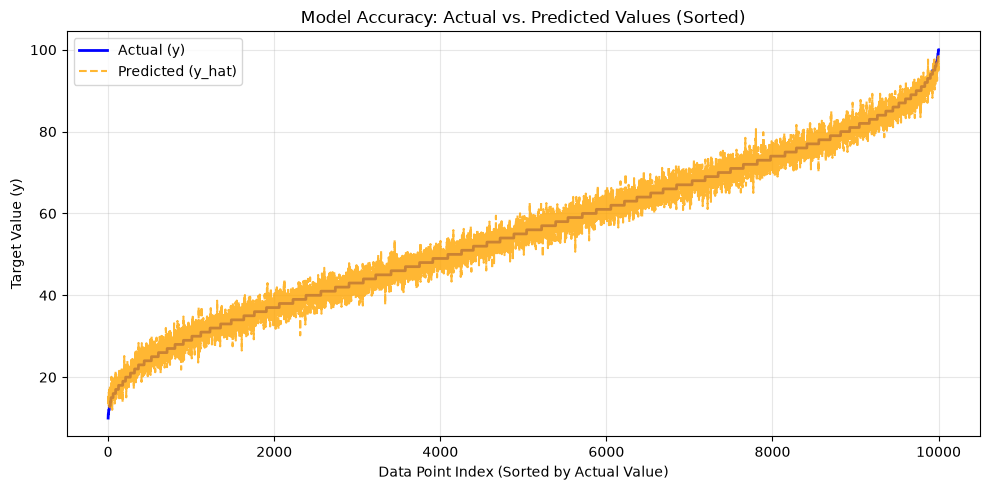

In [46]:
# 1. Flatten both to 1D arrays of shape (10000,)
vec_y_1d = vec_y.ravel()
f_wb_1d = f_wb.ravel()

# 2. Now argsort sorts down the 10,000 values properly
sorted_indices = np.argsort(vec_y_1d)
y_sorted = vec_y_1d[sorted_indices]
y_hat_sorted = f_wb_1d[sorted_indices]

# 2. Create the x-axis (sample index 0, 1, 2, ... m-1)
sample_index = np.arange(len(vec_y))

# 3. Plot both lines
plt.figure(figsize=(10, 5))
plt.plot(sample_index, y_sorted, label='Actual (y)', color='blue', linewidth=2)
plt.plot(sample_index, y_hat_sorted, label='Predicted (y_hat)', color='orange', linestyle='--', alpha=0.8)

# 4. Formatting
plt.title('Model Accuracy: Actual vs. Predicted Values (Sorted)')
plt.xlabel('Data Point Index (Sorted by Actual Value)')
plt.ylabel('Target Value (y)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
